### Data anatotation

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', None)

In [13]:
p    = './SToP-COVID_primary_drugs_T1_T2_T3_revised.xlsx'
data = pd.read_excel(p, sheet_name='wide')
data = data[~pd.isna(data.PID)]

### wide to long

In [14]:
df_long = pd.wide_to_long(data, 
                          stubnames=['Solitariness', 'Share', 'SCID', 'SDS', 
                                     'Frequency_of_use', 'Worry', 'Avoidance', 
                                     'Frequency_change'], 
                          i='PID', 
                          j='Timepoint', 
                          sep='_', 
                          suffix='[0-3]')
df_long = df_long.sort_values(['PID', 'Timepoint']).reset_index()

# Baseline primary drug retained as a time-invariant covariate
df_long['Primary'] = df_long['primary_T1']
display(df_long.head(5))

,PID,Timepoint,Age,Associated_with_physiological_disturbances_and_physical_factors,COC,Disorders_of_adult_personality_and_behaviour,Disorders_of_psychological_development‎,Due_to_psychoactive_substance_use,Gender,Infection status,KET,MES,MET,Mental_retardation,Method,Mood_disorders,Neurotic_stress_related_and_somatoform_disorders,Number of substance used,OPI,Onset_usually_occurring_in_childhood_and_adolescence,Organic_including_symptomatic_mental_disorders,Others,Schizophrenia_schizotypal_and_delusional_disorders,Shared equipment,THC,Vaccination status,primary_T1,primary_T2,primary_T3,Solitariness,Share,SCID,SDS,Frequency_of_use,Worry,Avoidance,Frequency_change,Primary
0,2.0,0,52.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,999.0,0.0,3,MES,MES,MES,5.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,MES
1,2.0,1,52.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,999.0,0.0,3,MES,MES,MES,1.0,0.0,1.0,1.0,6.0,0.0,0.0,3.0,MES
2,2.0,2,52.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,999.0,0.0,3,MES,MES,MES,1.0,0.0,1.0,1.0,6.0,0.0,0.0,3.0,MES
3,2.0,3,52.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,999.0,0.0,3,MES,MES,MES,1.0,0.0,3.0,1.0,6.0,0.0,0.0,3.0,MES
4,3.0,0,35.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,3.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,3,MET,MET,MET,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,MET


### data cleaning

In [15]:
# drugs = ['MET', 'THC', 'COC', 'MES', 'OPI', 'KET']

In [16]:
### data cleaning ###

df = df_long.copy()
df.replace({888: np.nan, 999: np.nan}, inplace=True)
df['Frequency'] = df['Frequency_of_use']
df['Time_cat']  = df['Timepoint'].map({0:'T0', 1:'T1', 2:'T2', 3:'T3'})
df['Avoid']  = df['Avoidance'].map({0:0, 1:1, 2:np.nan})
df['Share']  = df['Share'].map({0:0, 1:1, 2:np.nan})
df['ifVax'] = df['Vaccination status'].map({0:0, 1:0, 2:1, 3:1, 4:1}) # 2 doses
df['isInfected'] = df['Infection status '].map({0:0, 2:1, 3:1})
df['SCID'] = df['SCID'].replace({6:3})

drugs = ['MET', 'THC', 'COC', 'MES', 'OPI', 'KET']
for col in drugs: df[col] = df[col].replace({1:0.5, 0:-0.5})

comorbid = ['Due_to_psychoactive_substance_use',
        'Schizophrenia_schizotypal_and_delusional_disorders', 
        'Mood_disorders',
        'Disorders_of_adult_personality_and_behaviour',
        'Neurotic_stress_related_and_somatoform_disorders',
        'Onset_usually_occurring_in_childhood_and_adolescence',
        ]
for col in comorbid: df[col] = df[col].replace({1:0.5, 0:-0.5})
    
# df.rename(columns={'Disorders_of_psychological_development‎':'Disorders_of_psychological_development'}, inplace=True)
# col_others = ['Organic_including_symptomatic_mental_disorders',
# 'Associated_with_physiological_disturbances_and_physical_factors',
# 'Mental_retardation',
# 'Disorders_of_psychological_development',
# ]
# df['other_comorbidity'] = np.int64(df[col_others].sum(axis=1) != 0)
# df['other_comorbidity'] = df['other_comorbidity'].replace({1:0.5, 0:-0.5})

# df_t0 = df[df.Timepoint == 'T0'][['PID', 'Frequency']]
# df_t0 = df_t0.rename(columns={'Frequency': 'Frequency_B'})

df_final = df.copy()
# df_final = df_final[df_final.Time_cat != 'T0']
# df_final = pd.merge(df_final, df_t0, on='PID', how='left')

ls = ['PID', 'Time_cat', 'Timepoint',
      'Frequency', 'Solitariness', 'Avoid', 'Share',
      'Worry', 'SCID', 'ifVax', 'isInfected',
      'Gender', 'Age', 'Primary'] + drugs + comorbid

df_final = df_final[ls]
df_final.to_csv('./SToP-COVID_mlm.csv', index=False)
df_final.describe()

,PID,Timepoint,Frequency,Solitariness,Avoid,Share,Worry,SCID,ifVax,isInfected,Gender,Age,MET,THC,COC,MES,OPI,KET,Due_to_psychoactive_substance_use,Schizophrenia_schizotypal_and_delusional_disorders,Mood_disorders,Disorders_of_adult_personality_and_behaviour,Neurotic_stress_related_and_somatoform_disorders,Onset_usually_occurring_in_childhood_and_adolescence
count,520.000000,520.000000,312.000000,395.000000,265.000000,395.000000,312.000000,312.000000,500.000000,508.000000,520.000000,520.000000,520.00000,520.000000,520.000000,520.000000,520.000000,520.000000,520.000000,520.000000,520.000000,520.000000,520.000000,520.000000
mean,74.615385,1.500000,3.926282,2.805063,0.283019,0.574684,0.509615,1.714744,0.904000,0.283465,0.723077,40.030769,0.10000,-0.269231,-0.330769,-0.315385,-0.400000,-0.423077,0.123077,-0.369231,-0.238462,-0.446154,-0.292308,-0.438462
std,44.280832,1.119111,1.726756,1.585139,0.451318,0.495018,0.764929,1.104816,0.294886,0.451124,0.447909,11.004248,0.49037,0.421731,0.375317,0.388359,0.300289,0.266726,0.485082,0.337472,0.439896,0.225931,0.406046,0.240547
min,2.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,19.000000,-0.50000,-0.500000,-0.500000,-0.500000,-0.500000,-0.500000,-0.500000,-0.500000,-0.500000,-0.500000,-0.500000,-0.500000
25%,36.000000,0.750000,3.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,32.000000,-0.50000,-0.500000,-0.500000,-0.500000,-0.500000,-0.500000,-0.500000,-0.500000,-0.500000,-0.500000,-0.500000,-0.500000
50%,72.500000,1.500000,4.000000,2.000000,0.000000,1.000000,0.000000,2.000000,1.000000,0.000000,1.000000,40.500000,0.50000,-0.500000,-0.500000,-0.500000,-0.500000,-0.500000,0.500000,-0.500000,-0.500000,-0.500000,-0.500000,-0.500000
75%,112.000000,2.250000,5.250000,4.000000,1.000000,1.000000,1.000000,3.000000,1.000000,1.000000,1.000000,47.000000,0.50000,-0.500000,-0.500000,-0.500000,-0.500000,-0.500000,0.500000,-0.500000,0.500000,-0.500000,-0.500000,-0.500000
max,153.000000,3.000000,6.000000,5.000000,1.000000,1.000000,3.000000,3.000000,1.000000,1.000000,1.000000,65.000000,0.50000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000


### Figure

In [17]:
# df_final.groupby(['Time_cat'])['PID'].count()

In [18]:
# display(df_final.groupby(['Time_cat', 'SCID'])['PID'].count())

### Demographics

In [19]:
# display('Age')
# display(df_final.groupby('PID')[['Age']].apply(lambda x : np.unique(x)[0]).describe().reset_index())
# display('Gender')
# display(df_final.groupby('PID')[['Gender']].apply(lambda x : np.unique(x)[0]).value_counts())
# display(df_final.groupby('PID')[['Gender']].apply(lambda x : np.unique(x)[0]).describe().reset_index())

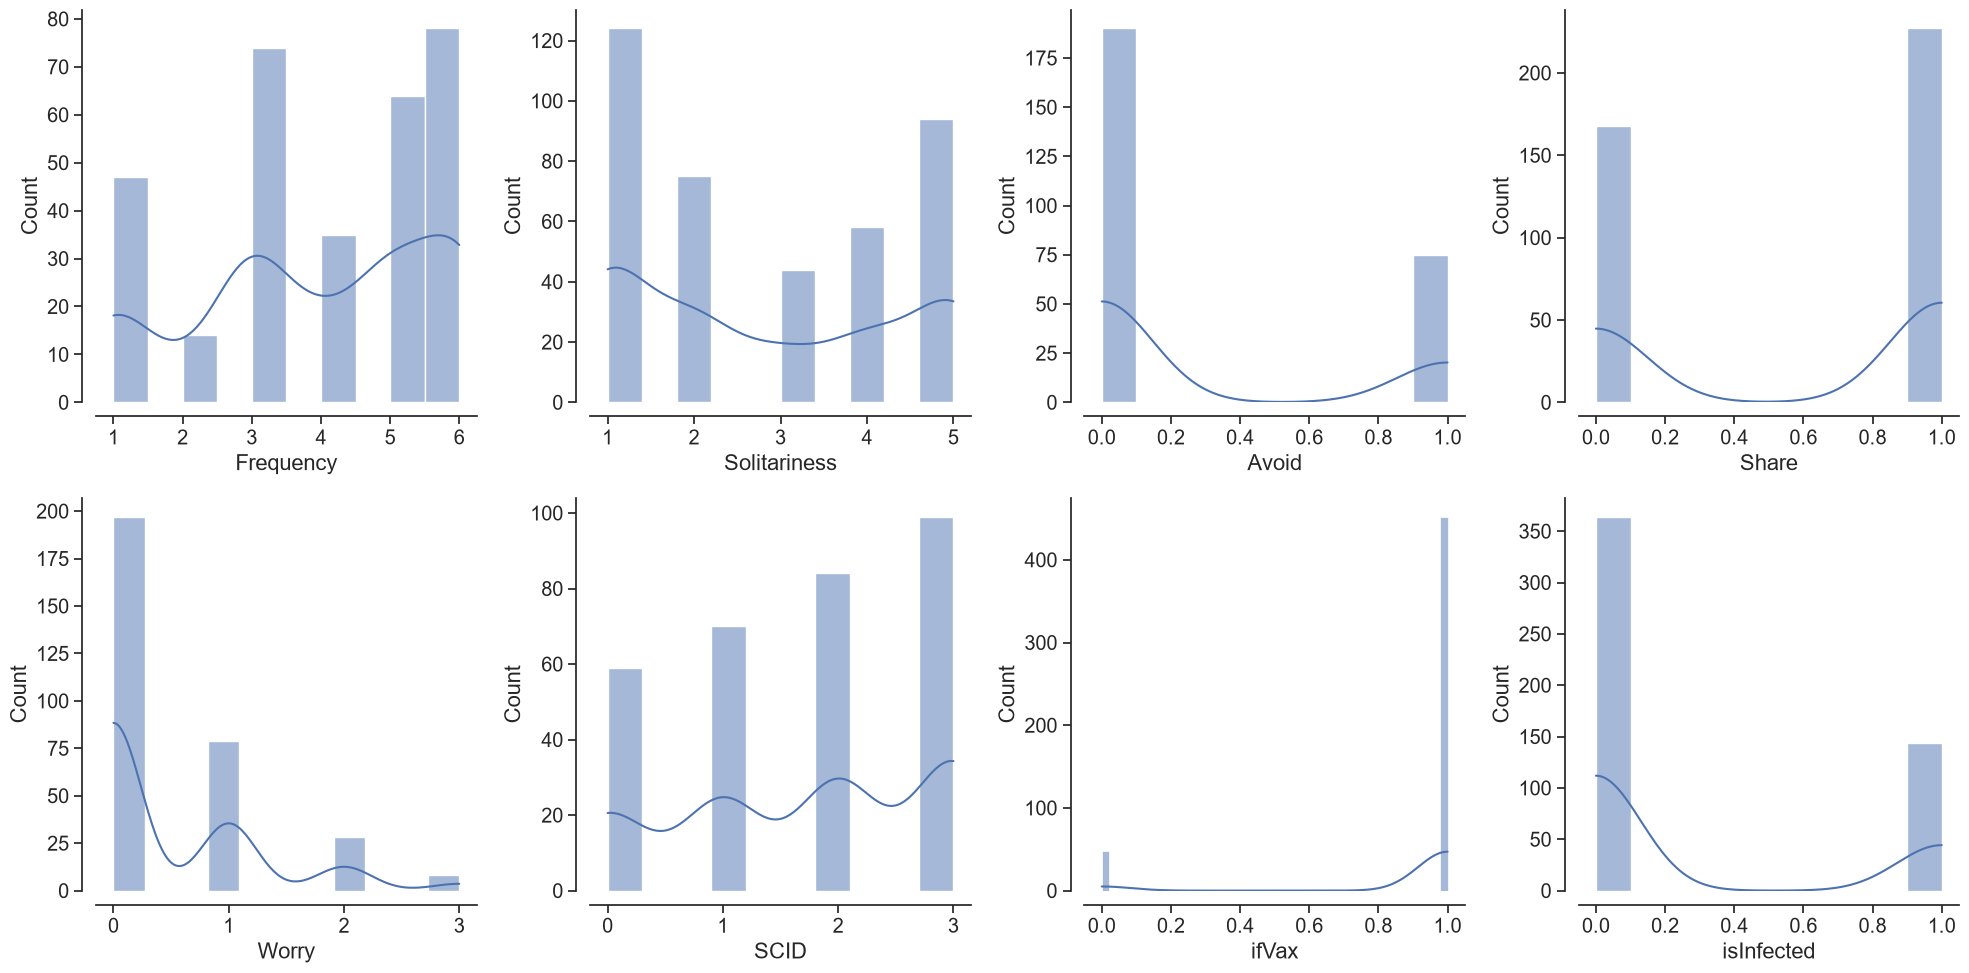

In [20]:
# %%capture

### Figure 2 SUPP ###

ls = ['Frequency', 'Solitariness', 'Avoid', 'Share', 'Worry', 'SCID', 'ifVax', 'isInfected']

# Set up #
sns.set_theme(style='ticks', font_scale=1.3)
rows, cols = (2, 4)
fig, axes  = plt.subplots(rows, cols, figsize=(20, 10), sharex=False, sharey=False)

ax_this = None
for r in range(rows):
    for c in range(cols):

        i = r*cols+c
        ax_this = axes[r][c]
        # Figure #
        sns.histplot(x=ls[i], kde=True, data=df_final, ax=ax_this)
#         ax_this.set(ylabel = ylabels[i], xlim=ylims[i], xlabel=None)
        sns.despine(top=True, right=True, offset=10, ax=ax_this)
        legend = ax_this.get_legend()

# Save #
fig.tight_layout()
fig.savefig(f'./Distribution.pdf')

In [21]:
df_final

,PID,Time_cat,Timepoint,Frequency,Solitariness,Avoid,Share,Worry,SCID,ifVax,isInfected,Gender,Age,Primary,MET,THC,COC,MES,OPI,KET,Due_to_psychoactive_substance_use,Schizophrenia_schizotypal_and_delusional_disorders,Mood_disorders,Disorders_of_adult_personality_and_behaviour,Neurotic_stress_related_and_somatoform_disorders,Onset_usually_occurring_in_childhood_and_adolescence
0,2.0,T0,0,NaN,5.0,NaN,0.0,NaN,NaN,1.0,0.0,1.0,52.0,MES,-0.5,-0.5,-0.5,0.5,-0.5,-0.5,0.5,-0.5,-0.5,-0.5,-0.5,-0.5
1,2.0,T1,1,6.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,52.0,MES,-0.5,-0.5,-0.5,0.5,-0.5,-0.5,0.5,-0.5,-0.5,-0.5,-0.5,-0.5
2,2.0,T2,2,6.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,52.0,MES,-0.5,-0.5,-0.5,0.5,-0.5,-0.5,0.5,-0.5,-0.5,-0.5,-0.5,-0.5
3,2.0,T3,3,6.0,1.0,0.0,0.0,0.0,3.0,1.0,0.0,1.0,52.0,MES,-0.5,-0.5,-0.5,0.5,-0.5,-0.5,0.5,-0.5,-0.5,-0.5,-0.5,-0.5
4,3.0,T0,0,NaN,1.0,NaN,1.0,NaN,NaN,1.0,0.0,0.0,35.0,MET,0.5,-0.5,-0.5,-0.5,-0.5,-0.5,0.5,-0.5,-0.5,-0.5,-0.5,-0.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
515,152.0,T3,3,3.0,5.0,1.0,0.0,1.0,3.0,0.0,1.0,1.0,53.0,MET,0.5,-0.5,-0.5,-0.5,-0.5,-0.5,0.5,-0.5,-0.5,-0.5,-0.5,-0.5
516,153.0,T0,0,NaN,2.0,NaN,0.0,NaN,NaN,1.0,0.0,1.0,26.0,MES,0.5,-0.5,-0.5,0.5,-0.5,-0.5,-0.5,-0.5,-0.5,-0.5,0.5,-0.5
517,153.0,T1,1,6.0,4.0,0.0,0.0,1.0,2.0,1.0,0.0,1.0,26.0,MES,0.5,-0.5,-0.5,0.5,-0.5,-0.5,-0.5,-0.5,-0.5,-0.5,0.5,-0.5
518,153.0,T2,2,6.0,1.0,0.0,0.0,2.0,3.0,1.0,0.0,1.0,26.0,MES,0.5,-0.5,-0.5,0.5,-0.5,-0.5,-0.5,-0.5,-0.5,-0.5,0.5,-0.5


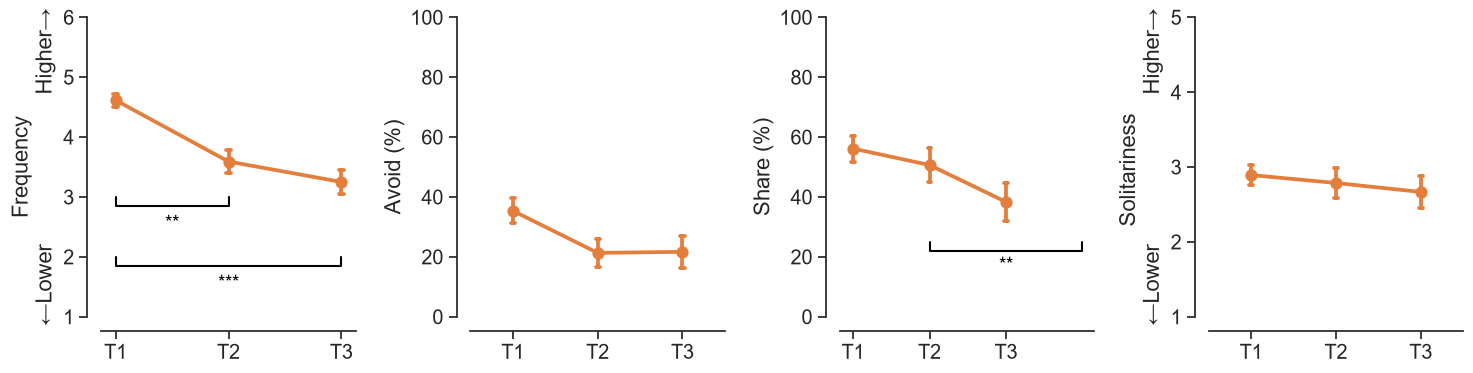

In [22]:
df_final['Share100'] = df.Share*100
df_final['Avoid100'] = df.Avoid*100

### IV ~ Time ###
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
sns.pointplot(y='Frequency', x='Time_cat', errorbar=('se', 1), capsize=.05, color='#E37E3D', data=df_final[df_final.Time_cat != 'T0'], ax=axes[0])
sns.pointplot(y='Avoid100', x='Time_cat',errorbar=('se', 1), capsize=.05, color='#E37E3D', data=df_final[df_final.Time_cat != 'T0'], ax=axes[1])
sns.pointplot(y='Share100', x='Time_cat', errorbar=('se', 1), capsize=.05, color='#E37E3D', data=df_final[df_final.Time_cat != 'T0'], ax=axes[2])
sns.pointplot(y='Solitariness', x='Time_cat', errorbar=('se', 1), capsize=.05, color='#E37E3D', data=df_final[df_final.Time_cat != 'T0'], ax=axes[3])

space = ' ' * 25
axes[0].set(ylim=(1, 6), ylabel=f'Frequency\n←Lower{space}Higher→', xlabel=None)
axes[1].set(ylim=(0, 100), ylabel='Avoid (%)', xlabel=None)
axes[2].set(ylim=(0, 100), ylabel='Share (%)', xlabel=None)
axes[3].set(ylim=(1, 5), yticks=[1, 2, 3, 4, 5], ylabel=f'Solitariness \n←Lower{space}Higher→', xlabel=None)
sns.despine(top=True, right=True, offset=10)

### significance ###
x1, x2 = 0, 1
y, h, col = 3, -0.15, 'black' 
axes[0].plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.5, c=col)
axes[0].text((x1+x2)*.5, y+h-0.45, "**", ha='center', va='bottom', color=col, fontsize=14)
x1, x2 = 0, 2
y, h, col = 2, -0.15, 'black' 
axes[0].plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.5, c=col)
axes[0].text((x1+x2)*.5, y+h-0.45, "***", ha='center', va='bottom', color=col, fontsize=14)
x1, x2 = 1, 3
y, h, col = 25, -3, 'black' 
axes[2].plot([x1, x1, x2, x2], [y, y+h, y+h, y], lw=1.5, c=col)
axes[2].text((x1+x2)*.5, y+h-8, "**", ha='center', va='bottom', color=col, fontsize=14)

fig.tight_layout()
fig.savefig(f'./outcome_over_time.pdf')

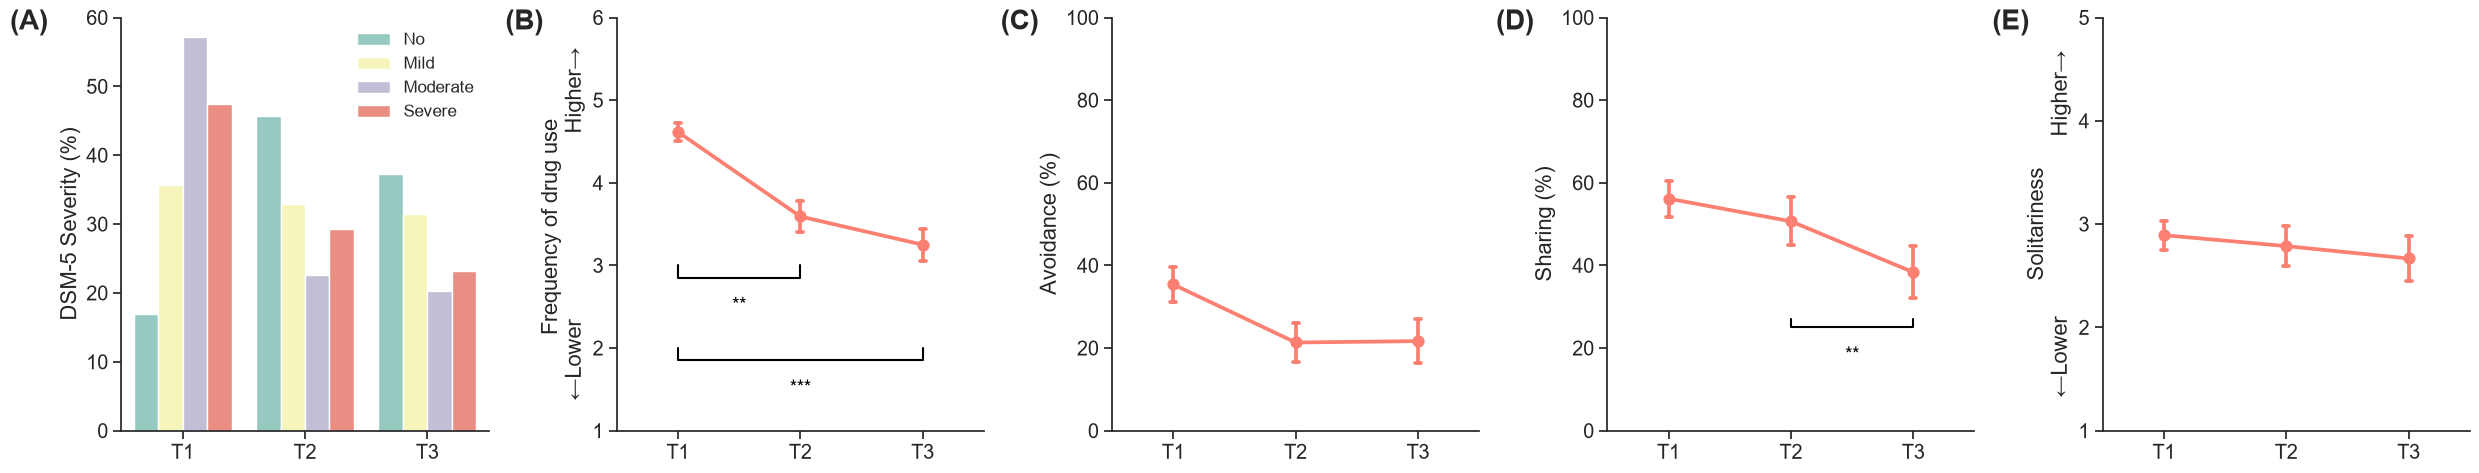

In [23]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Prepare data
df_final['Share100'] = df_final['Share'] * 100
df_final['Avoid100'] = df_final['Avoid'] * 100

# DSM-5: Convert SCID into categories
df_this = df_final[~np.isnan(df_final.SCID)].copy()
df_this['SCID_cat'] = df_this['SCID'].map({0: 'No', 1: 'Mild', 2: 'Moderate', 3: 'Severe'})

# Percentage counts for DSM-5
df_percent = (
    df_this[df_this['Time_cat'] != 'T0']
    .groupby(['Time_cat', 'SCID_cat'])
    .size()
    .reset_index(name='count')
)
df_percent['percent'] = df_percent.groupby('SCID_cat')['count'].transform(lambda x: 100 * x / x.sum())

# Palette for SCID categories
palette = {
    'No': '#8dd3c7',         # teal
    'Mild': '#ffffb3',       # yellow
    'Moderate': '#bebada',   # lavender
    'Severe': '#fb8072'      # salmon
}

scid_order = ['No', 'Mild', 'Moderate', 'Severe']
time_order = ['T1', 'T2', 'T3']

# Create subplots
fig, axes = plt.subplots(1, 5, figsize=(25, 5), sharex=False)

# DSM-5 (Barplot)
sns.barplot(
    data=df_percent,
    x='Time_cat',
    y='percent',
    hue='SCID_cat',
    hue_order=scid_order,
    order=time_order,
    palette=palette,
    ax=axes[0]
)
axes[0].set_ylabel('DSM-5 Severity (%)')
axes[0].set_xlabel(None)
axes[0].legend(frameon=False, fontsize=12)
sns.despine(ax=axes[0])

# Pointplots
sns.pointplot(y='Frequency', x='Time_cat', errorbar=('se', 1), capsize=.05, color='#fb8072',
              data=df_final[df_final.Time_cat != 'T0'], ax=axes[1])
axes[1].set(ylim=(1, 6), ylabel='Frequency of drug use \n←Lower                               Higher→', xlabel=None)

sns.pointplot(y='Avoid100', x='Time_cat', errorbar=('se', 1), capsize=.05, color='#fb8072',
              data=df_final[df_final.Time_cat != 'T0'], ax=axes[2])
axes[2].set(ylim=(0, 100), ylabel='Avoidance (%)', xlabel=None)

sns.pointplot(y='Share100', x='Time_cat', errorbar=('se', 1), capsize=.05, color='#fb8072',
              data=df_final[df_final.Time_cat != 'T0'], ax=axes[3])
axes[3].set(ylim=(0, 100), ylabel='Sharing (%)', xlabel=None)

sns.pointplot(y='Solitariness', x='Time_cat', errorbar=('se', 1), capsize=.05, color='#fb8072',
              data=df_final[df_final.Time_cat != 'T0'], ax=axes[4])
axes[4].set(ylim=(1, 5), yticks=[1, 2, 3, 4, 5], ylabel='Solitariness\n←Lower                              Higher→', xlabel=None)

# Clean up all axes
for ax in axes:
    sns.despine(ax=ax)
    ax.set_xlabel(None)

# Significance markers on Frequency and Share
axes[1].set(xlim=(-0.5, 2.5))
axes[1].plot([0, 0, 1, 1], [3, 2.85, 2.85, 3], lw=1.5, c='black')
axes[1].text(0.5, 2.4, "**", ha='center', va='bottom', color='black', fontsize=14)
axes[1].plot([0, 0, 2, 2], [2, 1.85, 1.85, 2], lw=1.5, c='black')
axes[1].text(1.0, 1.4, "***", ha='center', va='bottom', color='black', fontsize=14)
axes[3].set(xlim=(-0.5, 2.5))
axes[3].plot([1, 1, 2, 2], [27, 25, 25, 27], lw=1.5, c='black')
axes[3].text(1.5, 16, "**", ha='center', va='bottom', color='black', fontsize=14)

# Panel labels A–E
panel_labels = ['(A)', '(B)', '(C)', '(D)', '(E)']
for i, ax in enumerate(axes):
    ax.text(-0.2, 1.02, panel_labels[i], transform=ax.transAxes,
            fontsize=20, fontweight='bold', va='top', ha='right')

# Layout & Save
fig.tight_layout()
fig.savefig('./combined_outcomes_over_time.pdf')
plt.show()

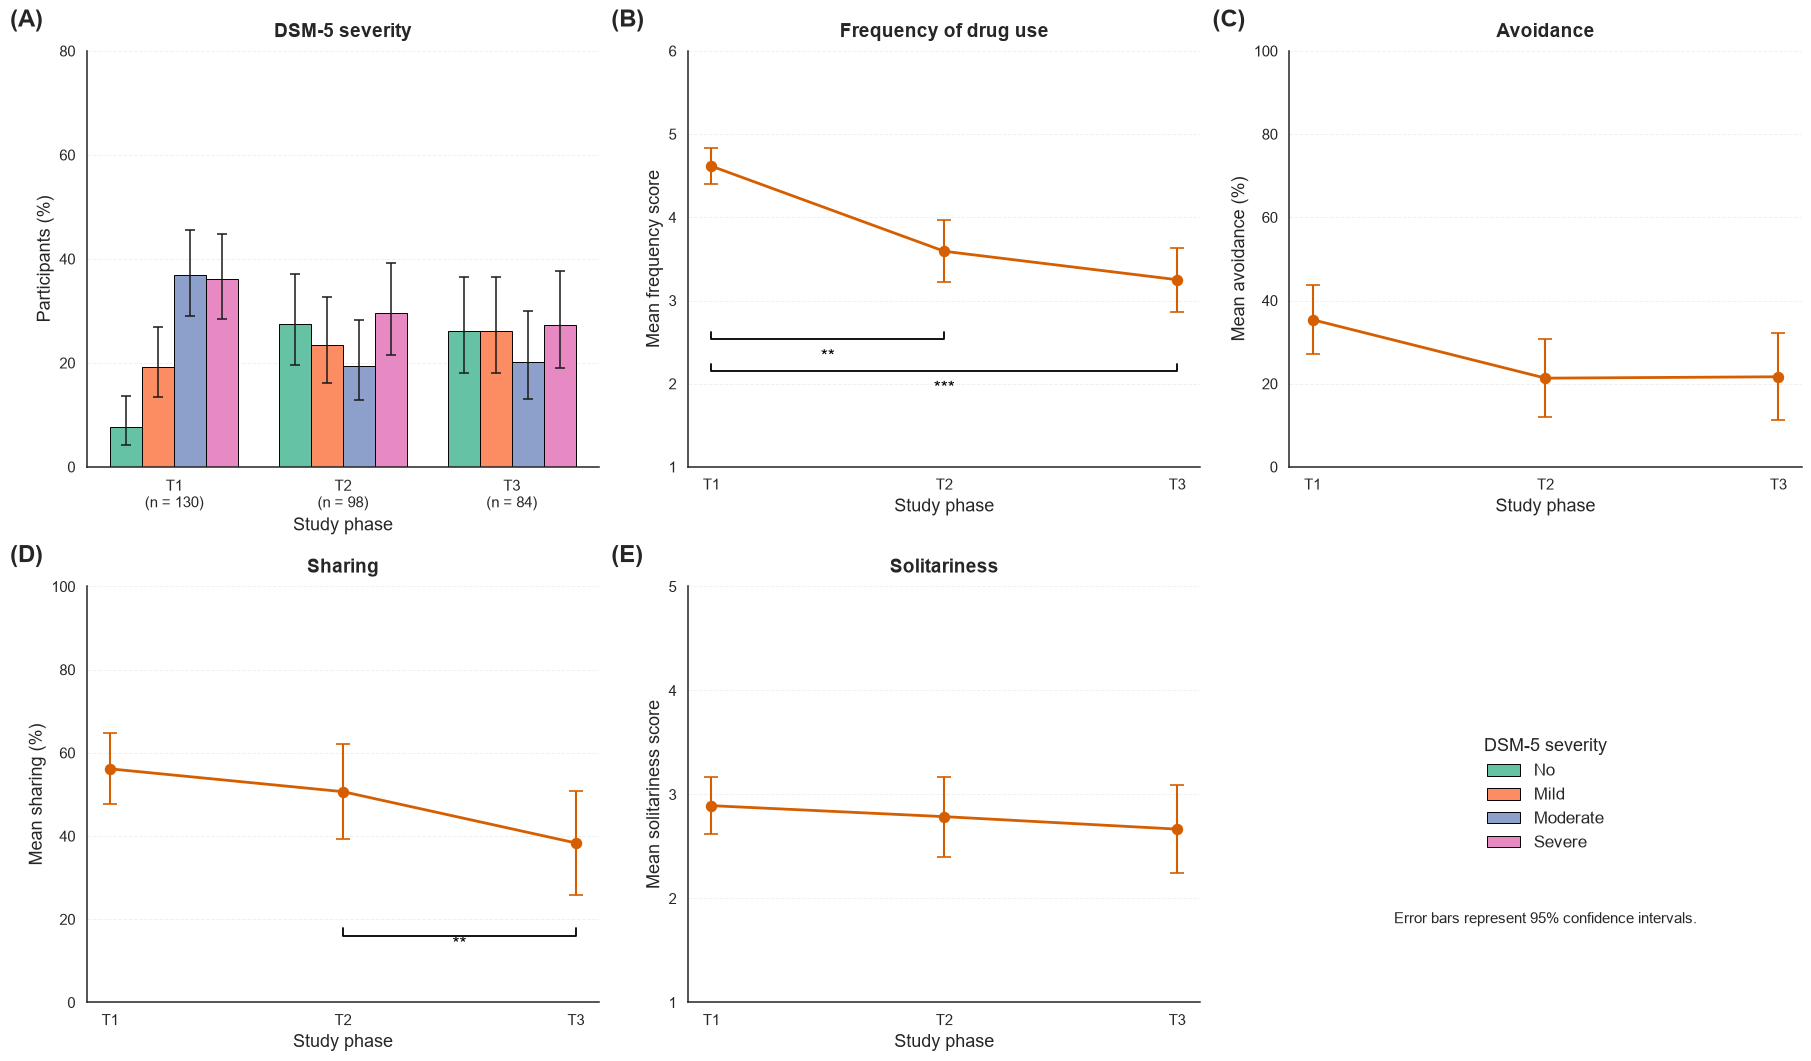

Vector PDF saved to: C:\Users\Administrator\Desktop\COVID revision\Dong's work\combined_outcomes_over_time_revised.pdf
900-dpi PNG saved to: C:\Users\Administrator\Desktop\COVID revision\Dong's work\combined_outcomes_over_time_revised_900dpi.png


In [24]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from pathlib import Path


# ============================================================
# 1. General publication settings
# ============================================================

sns.set_theme(
    style="white",
    context="paper",
    font_scale=1.35
)

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 12,
    "legend.title_fontsize": 13,
    "axes.linewidth": 1.1,
    "lines.linewidth": 2.0,

    # Preserve editable text in vector files
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})


# ============================================================
# 2. Prepare data
# ============================================================

time_order = ["T1", "T2", "T3"]

# Replace these labels with the actual study-phase names if desired.
time_labels = {
    "T1": "T1",
    "T2": "T2",
    "T3": "T3"
}

scid_order = ["No", "Mild", "Moderate", "Severe"]

scid_map = {
    0: "No",
    1: "Mild",
    2: "Moderate",
    3: "Severe"
}

plot_df = df_final.loc[
    df_final["Time_cat"].isin(time_order)
].copy()

# Ensure relevant variables are numeric
numeric_variables = [
    "SCID",
    "Frequency",
    "Avoid",
    "Share",
    "Solitariness"
]

for variable in numeric_variables:
    plot_df[variable] = pd.to_numeric(
        plot_df[variable],
        errors="coerce"
    )

plot_df[numeric_variables] = plot_df[numeric_variables].replace(
    [np.inf, -np.inf],
    np.nan
)

# Convert proportions into percentages
plot_df["Share100"] = plot_df["Share"] * 100
plot_df["Avoid100"] = plot_df["Avoid"] * 100

# Convert SCID scores into ordered severity categories
plot_df["SCID_cat"] = plot_df["SCID"].map(scid_map)

plot_df["SCID_cat"] = pd.Categorical(
    plot_df["SCID_cat"],
    categories=scid_order,
    ordered=True
)


# ============================================================
# 3. Prepare Panel A: SCID percentages and 95% Wilson CIs
# ============================================================

# Count each participant once within each study phase.
# This has no effect when each participant already has only one
# observation per phase.
scid_df = (
    plot_df
    .dropna(subset=["SCID", "SCID_cat", "PID"])
    .drop_duplicates(subset=["PID", "Time_cat"])
    .copy()
)

# Ensure all Time × SCID combinations are present,
# including combinations with zero observations.
complete_index = pd.MultiIndex.from_product(
    [time_order, scid_order],
    names=["Time_cat", "SCID_cat"]
)

scid_counts = (
    scid_df
    .groupby(["Time_cat", "SCID_cat"], observed=False)
    .size()
    .reindex(complete_index, fill_value=0)
    .rename("count")
    .reset_index()
)

# Total number of participants with non-missing SCID at each phase
scid_totals = (
    scid_df
    .groupby("Time_cat", observed=False)
    .size()
    .reindex(time_order, fill_value=0)
    .rename("n")
)

scid_percent = scid_counts.merge(
    scid_totals,
    left_on="Time_cat",
    right_index=True,
    how="left"
)

scid_percent["percent"] = np.where(
    scid_percent["n"] > 0,
    100 * scid_percent["count"] / scid_percent["n"],
    np.nan
)


def wilson_interval(count, n, z=1.959963984540054):
    """
    Calculate the 95% Wilson confidence interval for a proportion.

    Returns lower and upper confidence limits as percentages.
    """
    count = np.asarray(count, dtype=float)
    n = np.asarray(n, dtype=float)

    proportion = np.divide(
        count,
        n,
        out=np.full_like(count, np.nan, dtype=float),
        where=n > 0
    )

    denominator = 1 + (z ** 2 / n)

    centre = (
        proportion + (z ** 2 / (2 * n))
    ) / denominator

    half_width = (
        z
        * np.sqrt(
            proportion * (1 - proportion) / n
            + z ** 2 / (4 * n ** 2)
        )
        / denominator
    )

    lower = np.maximum(0, centre - half_width) * 100
    upper = np.minimum(1, centre + half_width) * 100

    return lower, upper


(
    scid_percent["ci_lower"],
    scid_percent["ci_upper"]
) = wilson_interval(
    scid_percent["count"],
    scid_percent["n"]
)

scid_percent["error_lower"] = (
    scid_percent["percent"] - scid_percent["ci_lower"]
)

scid_percent["error_upper"] = (
    scid_percent["ci_upper"] - scid_percent["percent"]
)


# ============================================================
# 4. Function for means and 95% CIs in Panels B–E
# ============================================================

def calculate_mean_ci(data, outcome):
    """
    Calculate the mean and normal-approximation 95% CI
    at each study phase.
    """
    summary = (
        data
        .dropna(subset=["Time_cat", outcome])
        .groupby("Time_cat", observed=False)[outcome]
        .agg(
            mean="mean",
            sd="std",
            n="count"
        )
        .reindex(time_order)
    )

    summary["se"] = summary["sd"] / np.sqrt(summary["n"])
    summary["ci95"] = 1.96 * summary["se"]

    return summary


def plot_mean_ci(
    ax,
    data,
    outcome,
    title,
    ylabel,
    ylim=None,
    yticks=None
):
    """
    Draw a mean line plot with 95% confidence intervals.
    """
    summary = calculate_mean_ci(data, outcome)

    x_positions = np.arange(len(time_order))

    ax.errorbar(
        x=x_positions,
        y=summary["mean"],
        yerr=summary["ci95"],
        marker="o",
        markersize=7,
        markeredgewidth=1.2,
        linewidth=2.0,
        elinewidth=1.5,
        capsize=5,
        capthick=1.5,
        color=sns.color_palette("colorblind")[3]
    )

    ax.set_xticks(x_positions)
    ax.set_xticklabels(
        [time_labels[t] for t in time_order]
    )

    ax.set_title(
        title,
        fontweight="bold",
        pad=10
    )

    ax.set_xlabel("Study phase")
    ax.set_ylabel(ylabel)

    if ylim is not None:
        ax.set_ylim(ylim)

    if yticks is not None:
        ax.set_yticks(yticks)

    ax.grid(
        axis="y",
        linestyle="--",
        linewidth=0.7,
        alpha=0.30
    )

    sns.despine(ax=ax)

    return summary


# ============================================================
# 5. Create revised 2 × 3 figure
# ============================================================

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(18, 10.5),
    constrained_layout=True
)

ax_a = axes[0, 0]
ax_b = axes[0, 1]
ax_c = axes[0, 2]
ax_d = axes[1, 0]
ax_e = axes[1, 1]

# Use the final panel for the legend
legend_ax = axes[1, 2]


# ============================================================
# Panel A: DSM-5/SCID severity percentages
# ============================================================

scid_colours = dict(
    zip(
        scid_order,
        sns.color_palette("Set2", n_colors=4)
    )
)

x_positions = np.arange(len(time_order))
bar_width = 0.19

for category_index, category in enumerate(scid_order):

    category_data = (
        scid_percent.loc[
            scid_percent["SCID_cat"] == category
        ]
        .set_index("Time_cat")
        .reindex(time_order)
    )

    offset = (
        category_index - (len(scid_order) - 1) / 2
    ) * bar_width

    y_errors = np.vstack([
        category_data["error_lower"].to_numpy(),
        category_data["error_upper"].to_numpy()
    ])

    ax_a.bar(
        x_positions + offset,
        category_data["percent"].to_numpy(),
        width=bar_width,
        label=category,
        color=scid_colours[category],
        edgecolor="black",
        linewidth=0.7,
        yerr=y_errors,
        capsize=3.5,
        error_kw={
            "elinewidth": 1.1,
            "capthick": 1.1
        }
    )

# Include sample size underneath each phase label
panel_a_tick_labels = []

for timepoint in time_order:
    sample_size = int(scid_totals.loc[timepoint])

    panel_a_tick_labels.append(
        f"{time_labels[timepoint]}\n(n = {sample_size})"
    )

ax_a.set_xticks(x_positions)
ax_a.set_xticklabels(panel_a_tick_labels)

ax_a.set_title(
    "DSM-5 severity",
    fontweight="bold",
    pad=10
)

ax_a.set_xlabel("Study phase")
ax_a.set_ylabel("Participants (%)")
ax_a.set_ylim(0, 80)
ax_a.set_yticks(np.arange(0, 81, 20))

ax_a.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.30
)

sns.despine(ax=ax_a)

# Transfer Panel A's legend to the unused sixth panel
legend_handles, legend_labels = ax_a.get_legend_handles_labels()

legend_ax.axis("off")

legend_ax.legend(
    legend_handles,
    legend_labels,
    title="DSM-5 severity",
    loc="center",
    frameon=False,
    ncol=1
)

legend_ax.text(
    0.5,
    0.20,
    "Error bars represent 95% confidence intervals.",
    transform=legend_ax.transAxes,
    ha="center",
    va="center",
    fontsize=11,
    wrap=True
)


# ============================================================
# Panel B: Frequency of drug use
# ============================================================

frequency_summary = plot_mean_ci(
    ax=ax_b,
    data=plot_df,
    outcome="Frequency",
    title="Frequency of drug use",
    ylabel="Mean frequency score",
    ylim=(1, 6),
    yticks=np.arange(1, 7, 1)
)


# ============================================================
# Panel C: Avoidance
# ============================================================

avoidance_summary = plot_mean_ci(
    ax=ax_c,
    data=plot_df,
    outcome="Avoid100",
    title="Avoidance",
    ylabel="Mean avoidance (%)",
    ylim=(0, 100),
    yticks=np.arange(0, 101, 20)
)


# ============================================================
# Panel D: Sharing
# ============================================================

sharing_summary = plot_mean_ci(
    ax=ax_d,
    data=plot_df,
    outcome="Share100",
    title="Sharing",
    ylabel="Mean sharing (%)",
    ylim=(0, 100),
    yticks=np.arange(0, 101, 20)
)


# ============================================================
# Panel E: Solitariness
# ============================================================

solitariness_summary = plot_mean_ci(
    ax=ax_e,
    data=plot_df,
    outcome="Solitariness",
    title="Solitariness",
    ylabel="Mean solitariness score",
    ylim=(1, 5),
    yticks=[1, 2, 3, 4, 5]
)


# ============================================================
# 6. Add significance brackets
# ============================================================

def add_significance_bracket(
    ax,
    x1,
    x2,
    y,
    height,
    text,
    fontsize=13
):
    """
    Add a significance bracket between two x-axis positions.
    """
    ax.plot(
        [x1, x1, x2, x2],
        [y, y + height, y + height, y],
        linewidth=1.3,
        color="black",
        clip_on=False
    )

    text_offset = 0.02 if height >= 0 else -0.12
    vertical_alignment = "bottom" if height >= 0 else "top"

    ax.text(
        (x1 + x2) / 2,
        y + height + text_offset,
        text,
        ha="center",
        va=vertical_alignment,
        fontsize=fontsize,
        color="black"
    )


# Frequency: T1 versus T2 and T1 versus T3
frequency_lower = (
    frequency_summary["mean"]
    - frequency_summary["ci95"]
)

frequency_data_bottom = np.nanmin(
    frequency_lower.to_numpy()
)

frequency_bracket_1 = max(1.35, frequency_data_bottom - 0.25)
frequency_bracket_2 = max(1.10, frequency_bracket_1 - 0.38)

add_significance_bracket(
    ax=ax_b,
    x1=0,
    x2=1,
    y=frequency_bracket_1,
    height=-0.08,
    text="**"
)

add_significance_bracket(
    ax=ax_b,
    x1=0,
    x2=2,
    y=frequency_bracket_2,
    height=-0.08,
    text="***"
)

ax_b.set_ylim(
    1,
    6
)


# Sharing: T2 versus T3
sharing_lower = (
    sharing_summary["mean"]
    - sharing_summary["ci95"]
)

sharing_data_bottom = np.nanmin(
    sharing_lower.to_numpy()
)

sharing_bracket = max(8, sharing_data_bottom - 8)

add_significance_bracket(
    ax=ax_d,
    x1=1,
    x2=2,
    y=sharing_bracket,
    height=-2,
    text="**"
)

ax_d.set_ylim(
    0,
    100
)


# ============================================================
# 7. Add panel labels A–E
# ============================================================

plot_axes = [
    ax_a,
    ax_b,
    ax_c,
    ax_d,
    ax_e
]

panel_labels = [
    "(A)",
    "(B)",
    "(C)",
    "(D)",
    "(E)"
]

for ax, label in zip(plot_axes, panel_labels):
    ax.text(
        -0.15,
        1.10,
        label,
        transform=ax.transAxes,
        fontsize=17,
        fontweight="bold",
        va="top",
        ha="left"
    )


# ============================================================
# 8. Save high-resolution outputs
# ============================================================

output_folder = Path(".")
pdf_file = output_folder / "combined_outcomes_over_time_revised.pdf"
png_file = output_folder / "combined_outcomes_over_time_revised_900dpi.png"

# PDF is vector-based and preferred for publication
fig.savefig(
    pdf_file,
    format="pdf",
    bbox_inches="tight",
    facecolor="white"
)

# High-resolution raster version
fig.savefig(
    png_file,
    format="png",
    dpi=900,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Vector PDF saved to: {pdf_file.resolve()}")
print(f"900-dpi PNG saved to: {png_file.resolve()}")